In [1]:
# pip install ccxt pandas numpy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ccxt
from datetime import datetime, timedelta

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Fonction Information Ratio

In [3]:
def information_ratio(
    strat_returns: pd.Series,
    bench_returns: pd.Series,
    periods_per_year: int = 365,
    annualize: bool = True,
    min_periods: int = 30,
) -> float:
    """
    Calcule l'Information Ratio entre une stratégie et son benchmark.

    Parameters
    ----------
    strat_returns : pd.Series - Rendements périodiques de la stratégie
    bench_returns : pd.Series - Rendements périodiques du benchmark
    periods_per_year : int - Facteur d'annualisation (365 pour crypto daily)
    annualize : bool - Si True, retourne l'IR annualisé
    min_periods : int - Minimum d'observations requises

    Returns
    -------
    float : Information Ratio (annualisé si annualize=True)
    """
    # Alignement sur les dates communes
    strat, bench = strat_returns.align(bench_returns, join="inner")

    # Rendements actifs
    active_returns = strat - bench
    active_returns = active_returns.dropna()

    if len(active_returns) < min_periods:
        return np.nan

    mean_active = active_returns.mean()
    tracking_error = active_returns.std(ddof=1)

    if tracking_error == 0:
        return np.nan

    ir = mean_active / tracking_error

    if annualize:
        ir = ir * np.sqrt(periods_per_year)

    return ir

## 2. Récupération des données via CCXT

In [4]:
def fetch_ohlcv(symbol: str, timeframe: str = '1d', days: int = 365) -> pd.DataFrame:
    """
    Récupère les données OHLCV depuis Binance via CCXT.
    """
    exchange = ccxt.binance()
    since = exchange.parse8601((datetime.now() - timedelta(days=days)).isoformat())
    
    ohlcv = exchange.fetch_ohlcv(symbol, timeframe, since=since, limit=1000)
    
    df = pd.DataFrame(ohlcv, columns=['timestamp', 'open', 'high', 'low', 'close', 'volume'])
    df['timestamp'] = pd.to_datetime(df['timestamp'], unit='ms')
    df.set_index('timestamp', inplace=True)
    
    return df

In [5]:
# Top 4 cryptos + benchmark
symbols = ['BTC/USDT', 'ETH/USDT', 'BNB/USDT', 'SOL/USDT']
benchmark_symbol = 'BTC/USDT'

# Récupération des données (1 an)
print("Récupération des données...")
prices = {}
for symbol in symbols:
    df = fetch_ohlcv(symbol, '1d', days=365)
    prices[symbol.split('/')[0]] = df['close']
    print(f"  {symbol}: {len(df)} jours")

# DataFrame des prix
prices_df = pd.DataFrame(prices)
prices_df = prices_df.dropna()
print(f"\nPériode: {prices_df.index[0].date()} → {prices_df.index[-1].date()}")
print(f"Observations: {len(prices_df)} jours")

Récupération des données...
  BTC/USDT: 365 jours
  ETH/USDT: 365 jours
  BNB/USDT: 365 jours
  SOL/USDT: 365 jours

Période: 2025-01-08 → 2026-01-07
Observations: 365 jours


## 3. Calcul des rendements

In [6]:
# Rendements journaliers
returns_df = prices_df.pct_change().dropna()

# Portefeuille équipondéré (25% chacun, rebalancé quotidiennement)
weights = np.array([0.25, 0.25, 0.25, 0.25])  # BTC, ETH, BNB, SOL
portfolio_returns = (returns_df * weights).sum(axis=1)

# Benchmark = BTC seul
benchmark_returns = returns_df['BTC']

print(f"Rendements calculés: {len(portfolio_returns)} observations")

Rendements calculés: 364 observations


## 4. Information Ratio : Résultat Global

In [7]:
ir = information_ratio(portfolio_returns, benchmark_returns, periods_per_year=365)
print(f"Information Ratio (annualisé) : {ir:.3f}")

# Contexte
if ir > 0.7:
    interpretation = "Surperformance régulière et significative"
elif ir > 0.3:
    interpretation = "Surperformance modeste mais détectable"
elif ir > 0:
    interpretation = "Légère surperformance, potentiellement du bruit"
else:
    interpretation = "Sous-performance vs benchmark"

print(f"Interprétation : {interpretation}")

Information Ratio (annualisé) : 0.456
Interprétation : Surperformance modeste mais détectable


## 5. Performance Comparée

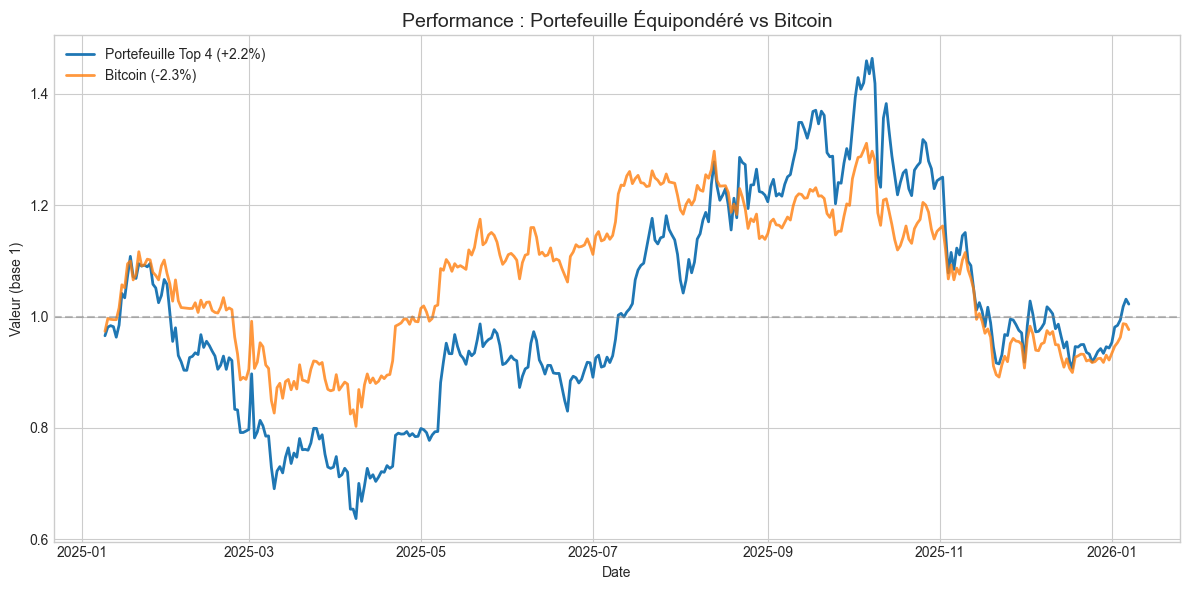


Performance Portefeuille : +2.2%
Performance Bitcoin      : -2.3%
Surperformance           : +4.6%


In [8]:
# Equity curves
portfolio_equity = (1 + portfolio_returns).cumprod()
benchmark_equity = (1 + benchmark_returns).cumprod()

# Performance totale
portfolio_perf = (portfolio_equity.iloc[-1] - 1) * 100
benchmark_perf = (benchmark_equity.iloc[-1] - 1) * 100

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(portfolio_equity.index, portfolio_equity, label=f'Portefeuille Top 4 ({portfolio_perf:+.1f}%)', linewidth=2)
ax.plot(benchmark_equity.index, benchmark_equity, label=f'Bitcoin ({benchmark_perf:+.1f}%)', linewidth=2, alpha=0.8)
ax.axhline(y=1, color='gray', linestyle='--', alpha=0.5)
ax.set_title('Performance : Portefeuille Équipondéré vs Bitcoin', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('Valeur (base 1)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print(f"\nPerformance Portefeuille : {portfolio_perf:+.1f}%")
print(f"Performance Bitcoin      : {benchmark_perf:+.1f}%")
print(f"Surperformance           : {portfolio_perf - benchmark_perf:+.1f}%")

## 6. Rolling Information Ratio (Stabilité)

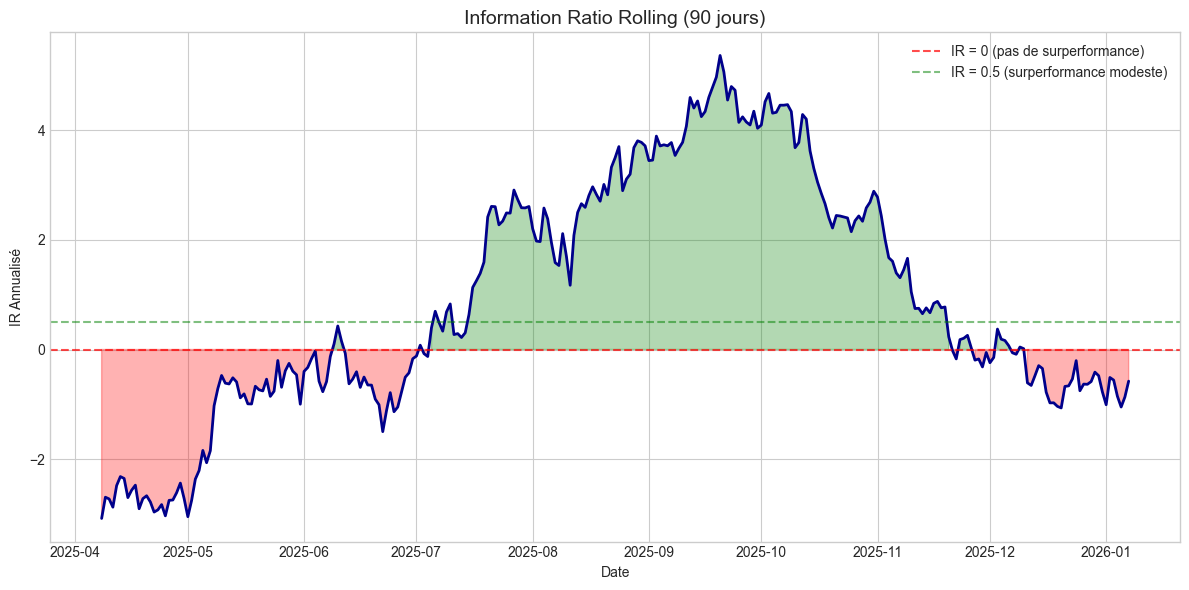


Pourcentage du temps avec IR > 0 : 55.6%
IR médian sur la période : 0.290


In [9]:
# Rendements actifs
active_returns = portfolio_returns - benchmark_returns

# Rolling IR (90 jours)
window = 90
rolling_mean = active_returns.rolling(window).mean()
rolling_std = active_returns.rolling(window).std()
rolling_ir = (rolling_mean / rolling_std) * np.sqrt(365)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(rolling_ir.index, rolling_ir, linewidth=2, color='darkblue')
ax.axhline(y=0, color='red', linestyle='--', alpha=0.7, label='IR = 0 (pas de surperformance)')
ax.axhline(y=0.5, color='green', linestyle='--', alpha=0.5, label='IR = 0.5 (surperformance modeste)')
ax.fill_between(rolling_ir.index, 0, rolling_ir, where=(rolling_ir > 0), alpha=0.3, color='green')
ax.fill_between(rolling_ir.index, 0, rolling_ir, where=(rolling_ir < 0), alpha=0.3, color='red')
ax.set_title(f'Information Ratio Rolling ({window} jours)', fontsize=14)
ax.set_xlabel('Date')
ax.set_ylabel('IR Annualisé')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Statistiques
ir_positive_pct = (rolling_ir > 0).sum() / rolling_ir.notna().sum() * 100
print(f"\nPourcentage du temps avec IR > 0 : {ir_positive_pct:.1f}%")
print(f"IR médian sur la période : {rolling_ir.median():.3f}")

## 8. Résumé

In [11]:
print("="*60)
print("RÉSUMÉ : INFORMATION RATIO")
print("="*60)
print(f"\nStratégie : Portefeuille équipondéré BTC/ETH/BNB/SOL")
print(f"Benchmark : Bitcoin (BTC)")
print(f"Période   : {prices_df.index[0].date()} → {prices_df.index[-1].date()}")
print(f"\n--- Performance ---")
print(f"Portefeuille : {portfolio_perf:+.1f}%")
print(f"Bitcoin      : {benchmark_perf:+.1f}%")
print(f"\n--- Information Ratio ---")
print(f"IR Global (annualisé) : {ir:.3f}")
print(f"IR Médian (rolling)   : {rolling_ir.median():.3f}")
print(f"% temps IR > 0        : {ir_positive_pct:.1f}%")
print("\n" + "="*60)

RÉSUMÉ : INFORMATION RATIO

Stratégie : Portefeuille équipondéré BTC/ETH/BNB/SOL
Benchmark : Bitcoin (BTC)
Période   : 2025-01-08 → 2026-01-07

--- Performance ---
Portefeuille : +2.2%
Bitcoin      : -2.3%

--- Information Ratio ---
IR Global (annualisé) : 0.456
IR Médian (rolling)   : 0.290
% temps IR > 0        : 55.6%

